Matplotlib is building the font cache; this may take a moment.


Cities: A, B, C, D, E


Enter starting city:  A
Enter destination city:  D



Shortest distance from A to all cities:
A : 0
B : 3
C : 2
D : 8
E : 10

Shortest path: A -> C -> B -> D
Total distance: 8


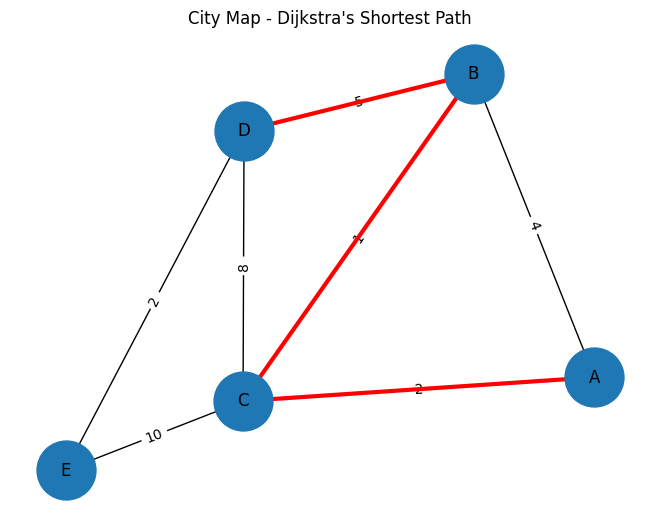

In [2]:

# Assignment 7: Dijkstra's Shortest Path Algorithm
# City Map using a Weighted Graph

import heapq
import networkx as nx
import matplotlib.pyplot as plt


# Graph: city -> neighbouring cities and distances
graph = {
    "A": {"B": 4, "C": 2},
    "B": {"A": 4, "C": 1, "D": 5},
    "C": {"A": 2, "B": 1, "D": 8, "E": 10},
    "D": {"B": 5, "C": 8, "E": 2},
    "E": {"C": 10, "D": 2}
}


# Dijkstra's Algorithm
def dijkstra(graph, start):
    distance = {city: float("inf") for city in graph}
    previous = {city: None for city in graph}

    distance[start] = 0
    priority_queue = [(0, start)]

    while priority_queue:
        current_distance, city = heapq.heappop(priority_queue)

        # Ignore outdated queue entries
        if current_distance > distance[city]:
            continue

        for neighbour, weight in graph[city].items():
            new_distance = current_distance + weight

            if new_distance < distance[neighbour]:
                distance[neighbour] = new_distance
                previous[neighbour] = city

                heapq.heappush(
                    priority_queue,
                    (new_distance, neighbour)
                )

    return distance, previous


# Reconstruct shortest path
def get_path(previous, start, end):
    path = []
    city = end

    while city is not None:
        path.append(city)
        city = previous[city]

    path.reverse()

    if path[0] == start:
        return path

    return []


# Display graph
def visualize_graph(graph, path):
    G = nx.Graph()

    for city, neighbours in graph.items():
        for neighbour, distance in neighbours.items():
            G.add_edge(city, neighbour, weight=distance)

    pos = nx.spring_layout(G, seed=10)

    nx.draw(
        G, pos, with_labels=True,
        node_size=1800, font_size=12
    )

    edge_labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=edge_labels
    )

    # Highlight shortest path
    if len(path) > 1:
        path_edges = list(zip(path, path[1:]))

        nx.draw_networkx_edges(
            G, pos, edgelist=path_edges,
            edge_color="red", width=3
        )

    plt.title("City Map - Dijkstra's Shortest Path")
    plt.show()


# Main Program
print("Cities:", ", ".join(graph.keys()))

start = input("Enter starting city: ").upper()
end = input("Enter destination city: ").upper()

if start not in graph or end not in graph:
    print("Invalid city!")
else:
    distances, previous = dijkstra(graph, start)
    path = get_path(previous, start, end)

    print("\nShortest distance from", start, "to all cities:")

    for city in graph:
        print(city, ":", distances[city])

    if path:
        print("\nShortest path:", " -> ".join(path))
        print("Total distance:", distances[end])
    else:
        print("No path exists.")

    visualize_graph(graph, path)
